# FICE Predictions vs True Values Visualization

Simple scatter plots showing model predictions vs true cardinality values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set up matplotlib for better plots
plt.style.use('default')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

## Load and Examine the Data

First, let's load both training and test data files and examine their structure.

In [2]:
# Load the data files
train_data = pd.read_csv('files/train_values.csv')
test_data = pd.read_csv('files/test_values.csv')

print("Training Data Shape:", train_data.shape)
print("Test Data Shape:", test_data.shape)
print("Training Data Columns:", train_data.columns.tolist())

Training Data Shape: (200000, 6)
Test Data Shape: (50000, 6)
Training Data Columns: ['epoch', 'batch_idx', 'prediction_log', 'true_value_log', 'prediction', 'true_value']


## Training Data: Predictions vs True Values

All epochs: 50 (from 1 to 50)
Using last 5 epochs: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]
Training data after filtering to last 5 epochs: 20000 points


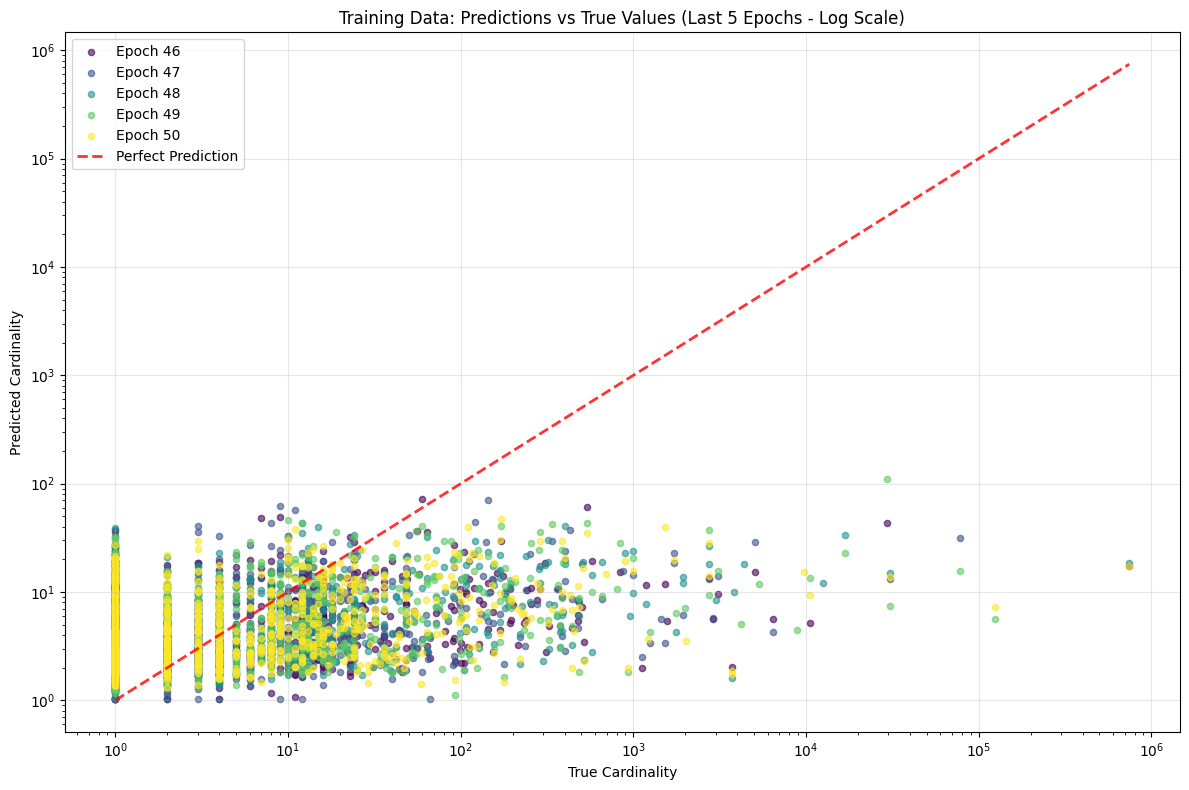


Prediction range: 1.02 to 159.98
True value range: 1.00 to 745200.00
Epochs analyzed: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]


In [3]:
# Get the last 5 epochs from training data
all_epochs = sorted(train_data['epoch'].unique())
last_5_epochs = all_epochs[-5:] if len(all_epochs) >= 5 else all_epochs

print(f"All epochs: {len(all_epochs)} (from {min(all_epochs)} to {max(all_epochs)})")
print(f"Using last 5 epochs: {last_5_epochs}")

# Filter training data to last 5 epochs
train_filtered = train_data[train_data['epoch'].isin(last_5_epochs)].copy()

# Clean the training data - remove infinite predictions
train_filtered['prediction_clean'] = train_filtered['prediction'].replace([np.inf, -np.inf], np.nan)
train_filtered = train_filtered.dropna(subset=['prediction_clean'])

print(f"Training data after filtering to last 5 epochs: {len(train_filtered)} points")

# Create scatter plot for training data with different colors per epoch
plt.figure(figsize=(12, 8))

# Define colors for epochs
colors = plt.cm.viridis(np.linspace(0, 1, len(last_5_epochs)))
color_map = dict(zip(last_5_epochs, colors))

# Plot each epoch with different colors
for i, epoch in enumerate(last_5_epochs):
    epoch_data = train_filtered[train_filtered['epoch'] == epoch]
    
    # Sample data if too many points
    sample_size = min(1000, len(epoch_data))  # Limit per epoch for better visualization
    if len(epoch_data) > sample_size:
        epoch_sample = epoch_data.sample(n=sample_size, random_state=42)
    else:
        epoch_sample = epoch_data
    
    plt.scatter(epoch_sample['true_value'], epoch_sample['prediction_clean'], 
               alpha=0.6, s=20, c=[colors[i]], label=f'Epoch {epoch}')

# Add perfect prediction line (y=x)
max_val = train_filtered['true_value'].max()
min_val = train_filtered['true_value'].min()
max_pred = train_filtered['prediction_clean'].max()
min_pred = train_filtered['prediction_clean'].min()

overall_max = max(max_val, max_pred)
overall_min = min(min_val, min_pred)

plt.plot([overall_min, overall_max], [overall_min, overall_max], 'r--', alpha=0.8, linewidth=2, label='Perfect Prediction')

plt.xlabel('True Cardinality')
plt.ylabel('Predicted Cardinality')
plt.title(f'Training Data: Predictions vs True Values (Last 5 Epochs)')
plt.legend()
plt.grid(True, alpha=0.3)

# Use log scale if the range is large
if overall_max / overall_min > 100:
    plt.xscale('log')
    plt.yscale('log')
    plt.title(f'Training Data: Predictions vs True Values (Last 5 Epochs - Log Scale)')

plt.tight_layout()
plt.show()

# Print some basic statistics
print(f"\nPrediction range: {train_filtered['prediction_clean'].min():.2f} to {train_filtered['prediction_clean'].max():.2f}")
print(f"True value range: {train_filtered['true_value'].min():.2f} to {train_filtered['true_value'].max():.2f}")
print(f"Epochs analyzed: {last_5_epochs}")

In [4]:
## Test Data: Predictions vs True Values

Test epochs: 50 (from 1 to 50)
Using last 5 test epochs: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]
Test data after filtering to last 5 epochs: 5000 points


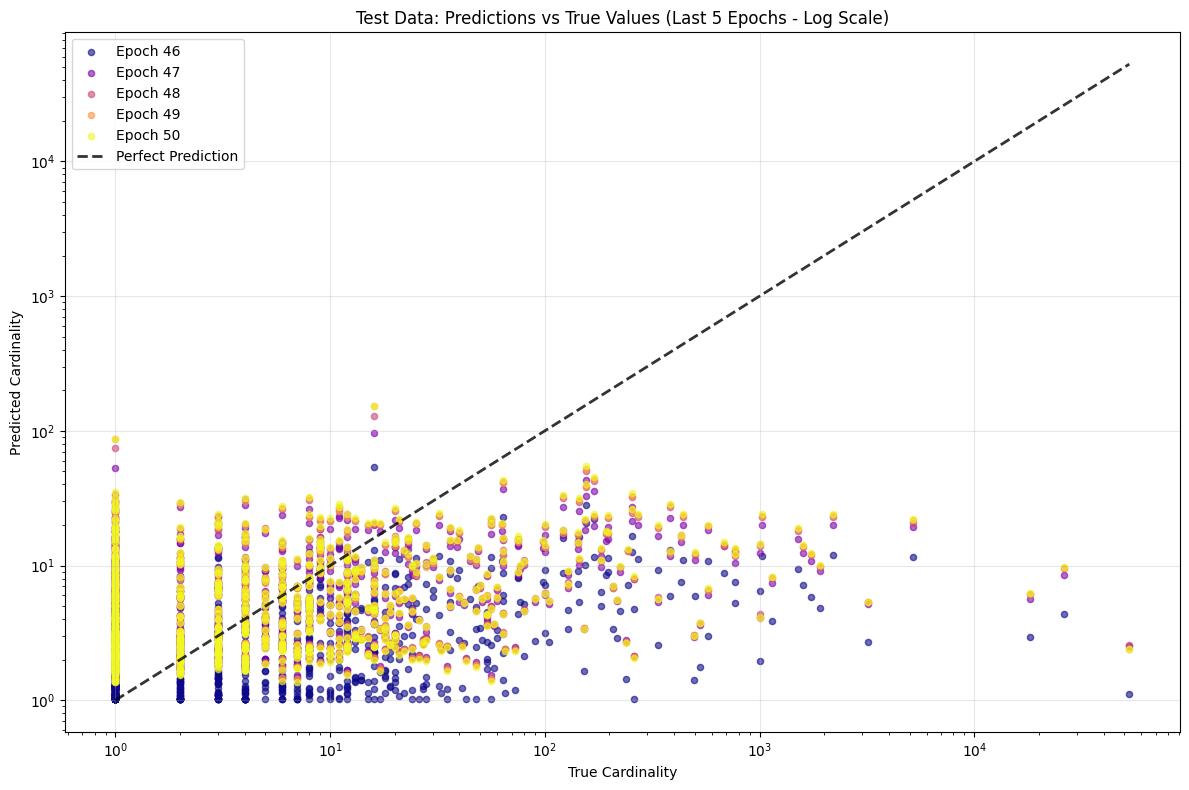


Prediction range: 1.02 to 153.21
True value range: 1.00 to 52737.00
Epochs analyzed: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]


In [5]:
# Get the last 5 epochs from test data
test_all_epochs = sorted(test_data['epoch'].unique())
test_last_5_epochs = test_all_epochs[-5:] if len(test_all_epochs) >= 5 else test_all_epochs

print(f"Test epochs: {len(test_all_epochs)} (from {min(test_all_epochs)} to {max(test_all_epochs)})")
print(f"Using last 5 test epochs: {test_last_5_epochs}")

# Filter test data to last 5 epochs
test_filtered = test_data[test_data['epoch'].isin(test_last_5_epochs)].copy()

# Clean the test data - remove infinite predictions
test_filtered['prediction_clean'] = test_filtered['prediction'].replace([np.inf, -np.inf], np.nan)
test_filtered = test_filtered.dropna(subset=['prediction_clean'])

print(f"Test data after filtering to last 5 epochs: {len(test_filtered)} points")

# Create scatter plot for test data with different colors per epoch
plt.figure(figsize=(12, 8))

# Define colors for epochs
colors = plt.cm.plasma(np.linspace(0, 1, len(test_last_5_epochs)))
color_map = dict(zip(test_last_5_epochs, colors))

# Plot each epoch with different colors
for i, epoch in enumerate(test_last_5_epochs):
    epoch_data = test_filtered[test_filtered['epoch'] == epoch]
    
    # Sample data if too many points
    sample_size = min(1000, len(epoch_data))  # Limit per epoch for better visualization
    if len(epoch_data) > sample_size:
        epoch_sample = epoch_data.sample(n=sample_size, random_state=42)
    else:
        epoch_sample = epoch_data
    
    plt.scatter(epoch_sample['true_value'], epoch_sample['prediction_clean'], 
               alpha=0.6, s=20, c=[colors[i]], label=f'Epoch {epoch}')

# Add perfect prediction line (y=x)
max_val = test_filtered['true_value'].max()
min_val = test_filtered['true_value'].min()
max_pred = test_filtered['prediction_clean'].max()
min_pred = test_filtered['prediction_clean'].min()

overall_max = max(max_val, max_pred)
overall_min = min(min_val, min_pred)

plt.plot([overall_min, overall_max], [overall_min, overall_max], 'k--', alpha=0.8, linewidth=2, label='Perfect Prediction')

plt.xlabel('True Cardinality')
plt.ylabel('Predicted Cardinality')
plt.title(f'Test Data: Predictions vs True Values (Last 5 Epochs)')
plt.legend()
plt.grid(True, alpha=0.3)

# Use log scale if the range is large
if overall_max / overall_min > 100:
    plt.xscale('log')
    plt.yscale('log')
    plt.title(f'Test Data: Predictions vs True Values (Last 5 Epochs - Log Scale)')

plt.tight_layout()
plt.show()

# Print some basic statistics
print(f"\nPrediction range: {test_filtered['prediction_clean'].min():.2f} to {test_filtered['prediction_clean'].max():.2f}")
print(f"True value range: {test_filtered['true_value'].min():.2f} to {test_filtered['true_value'].max():.2f}")
print(f"Epochs analyzed: {test_last_5_epochs}")

## Combined View: Training and Test Data

Common epochs for combined plot: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]


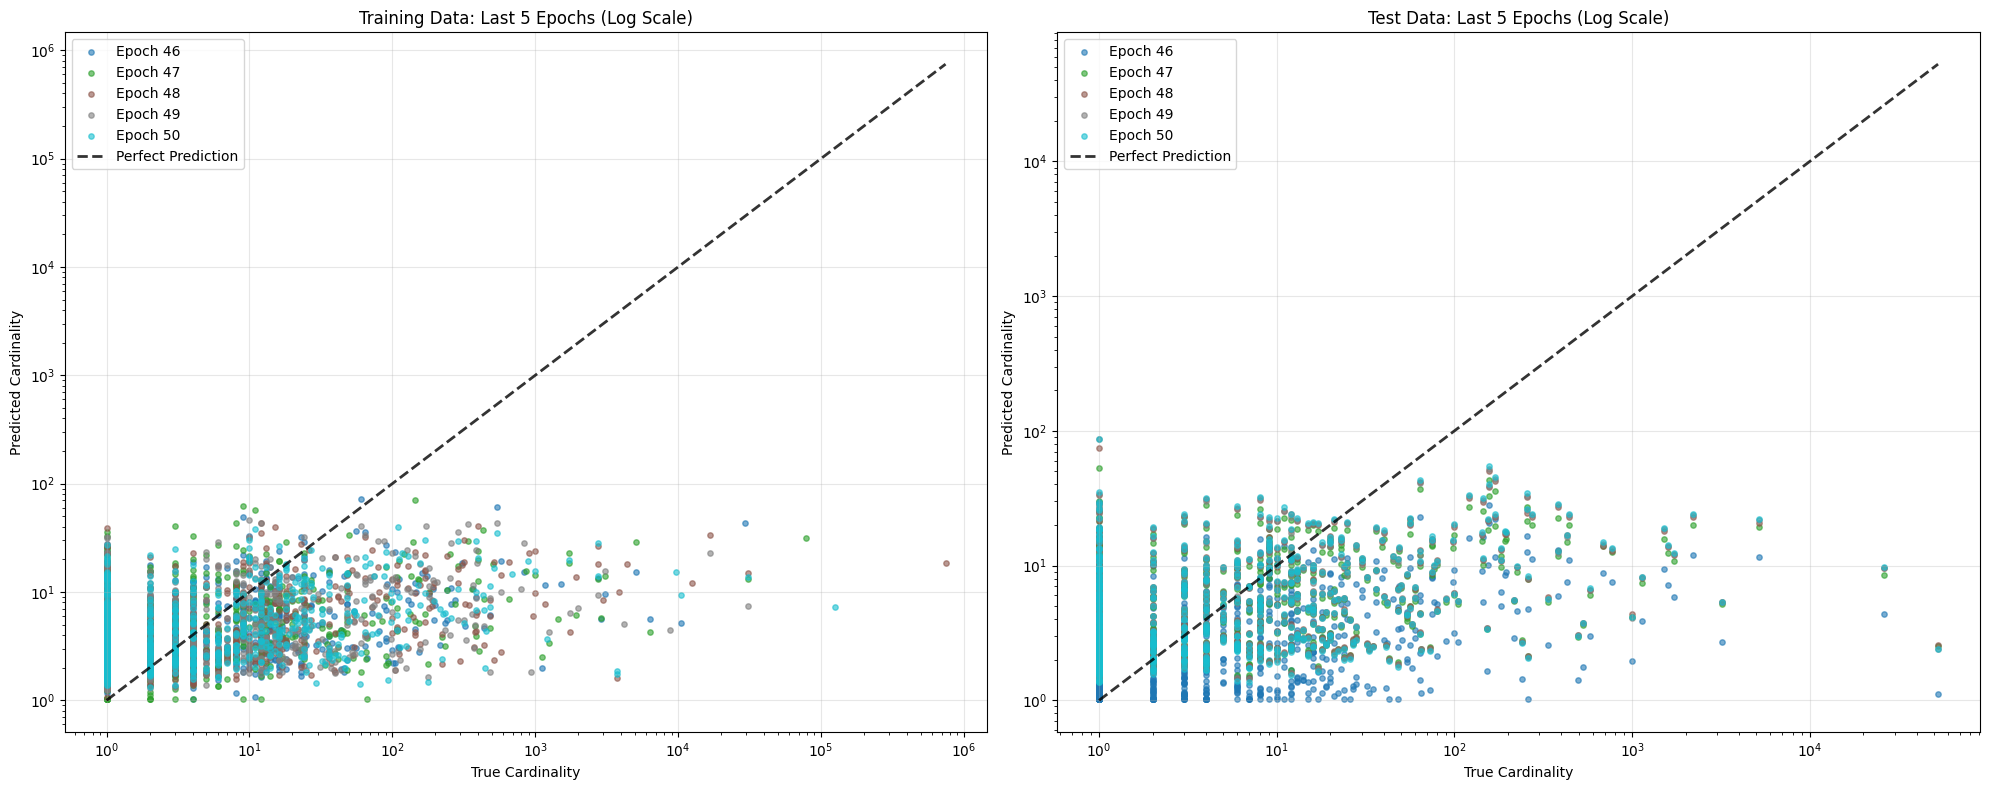


Analyzed epochs: [np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]
Training data points: 20000
Test data points: 5000


In [6]:
# Create a combined plot showing both training and test data for last 5 epochs
# Use common epochs between train and test
common_epochs = list(set(last_5_epochs) & set(test_last_5_epochs))
common_epochs.sort()

if len(common_epochs) == 0:
    print("No common epochs between training and test data!")
    common_epochs = last_5_epochs[:min(5, len(last_5_epochs))]

print(f"Common epochs for combined plot: {common_epochs}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Define colors for epochs
colors = plt.cm.tab10(np.linspace(0, 1, len(common_epochs)))

# Plot 1: Training data
for i, epoch in enumerate(common_epochs):
    train_epoch_data = train_filtered[train_filtered['epoch'] == epoch]
    
    # Sample data if too many points
    sample_size = min(800, len(train_epoch_data))
    if len(train_epoch_data) > sample_size:
        train_epoch_sample = train_epoch_data.sample(n=sample_size, random_state=42)
    else:
        train_epoch_sample = train_epoch_data
    
    if len(train_epoch_sample) > 0:
        ax1.scatter(train_epoch_sample['true_value'], train_epoch_sample['prediction_clean'], 
                   alpha=0.6, s=15, c=[colors[i]], label=f'Epoch {epoch}')

# Add perfect prediction line for training
if len(train_filtered) > 0:
    train_max = max(train_filtered['true_value'].max(), train_filtered['prediction_clean'].max())
    train_min = min(train_filtered['true_value'].min(), train_filtered['prediction_clean'].min())
    ax1.plot([train_min, train_max], [train_min, train_max], 'k--', alpha=0.8, linewidth=2, label='Perfect Prediction')

ax1.set_xlabel('True Cardinality')
ax1.set_ylabel('Predicted Cardinality')
ax1.set_title(f'Training Data: Last {len(common_epochs)} Epochs')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Use log scale for training if needed
if len(train_filtered) > 0 and train_max / train_min > 100:
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_title(f'Training Data: Last {len(common_epochs)} Epochs (Log Scale)')

# Plot 2: Test data
for i, epoch in enumerate(common_epochs):
    test_epoch_data = test_filtered[test_filtered['epoch'] == epoch]
    
    # Sample data if too many points
    sample_size = min(800, len(test_epoch_data))
    if len(test_epoch_data) > sample_size:
        test_epoch_sample = test_epoch_data.sample(n=sample_size, random_state=42)
    else:
        test_epoch_sample = test_epoch_data
    
    if len(test_epoch_sample) > 0:
        ax2.scatter(test_epoch_sample['true_value'], test_epoch_sample['prediction_clean'], 
                   alpha=0.6, s=15, c=[colors[i]], label=f'Epoch {epoch}')

# Add perfect prediction line for test
if len(test_filtered) > 0:
    test_max = max(test_filtered['true_value'].max(), test_filtered['prediction_clean'].max())
    test_min = min(test_filtered['true_value'].min(), test_filtered['prediction_clean'].min())
    ax2.plot([test_min, test_max], [test_min, test_max], 'k--', alpha=0.8, linewidth=2, label='Perfect Prediction')

ax2.set_xlabel('True Cardinality')
ax2.set_ylabel('Predicted Cardinality')
ax2.set_title(f'Test Data: Last {len(common_epochs)} Epochs')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Use log scale for test if needed
if len(test_filtered) > 0 and test_max / test_min > 100:
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_title(f'Test Data: Last {len(common_epochs)} Epochs (Log Scale)')

plt.tight_layout()
plt.show()

print(f"\nAnalyzed epochs: {common_epochs}")
print(f"Training data points: {len(train_filtered)}")
print(f"Test data points: {len(test_filtered)}")

## Epoch-wise Summary Statistics

In [7]:
# Calculate and display statistics for each epoch
print("=== EPOCH-WISE STATISTICS ===\n")

print("TRAINING DATA:")
print("-" * 50)
for epoch in last_5_epochs:
    epoch_data = train_filtered[train_filtered['epoch'] == epoch]
    if len(epoch_data) > 0:
        pred_mean = epoch_data['prediction_clean'].mean()
        true_mean = epoch_data['true_value'].mean()
        mse = ((epoch_data['prediction_clean'] - epoch_data['true_value']) ** 2).mean()
        mae = (np.abs(epoch_data['prediction_clean'] - epoch_data['true_value'])).mean()
        
        print(f"Epoch {epoch}:")
        print(f"  Points: {len(epoch_data)}")
        print(f"  Avg Prediction: {pred_mean:.2f}")
        print(f"  Avg True Value: {true_mean:.2f}")
        print(f"  MSE: {mse:.2f}")
        print(f"  MAE: {mae:.2f}")
        print()

print("\nTEST DATA:")
print("-" * 50)
for epoch in test_last_5_epochs:
    epoch_data = test_filtered[test_filtered['epoch'] == epoch]
    if len(epoch_data) > 0:
        pred_mean = epoch_data['prediction_clean'].mean()
        true_mean = epoch_data['true_value'].mean()
        mse = ((epoch_data['prediction_clean'] - epoch_data['true_value']) ** 2).mean()
        mae = (np.abs(epoch_data['prediction_clean'] - epoch_data['true_value'])).mean()
        
        print(f"Epoch {epoch}:")
        print(f"  Points: {len(epoch_data)}")
        print(f"  Avg Prediction: {pred_mean:.2f}")
        print(f"  Avg True Value: {true_mean:.2f}")
        print(f"  MSE: {mse:.2f}")
        print(f"  MAE: {mae:.2f}")
        print()

# Show data quality info
train_inf_count = (train_data[train_data['epoch'].isin(last_5_epochs)]['prediction'] == np.inf).sum()
test_inf_count = (test_data[test_data['epoch'].isin(test_last_5_epochs)]['prediction'] == np.inf).sum()

total_train_points = len(train_data[train_data['epoch'].isin(last_5_epochs)])
total_test_points = len(test_data[test_data['epoch'].isin(test_last_5_epochs)])

print(f"\nDATA QUALITY (Last 5 Epochs):")
print(f"Training: {train_inf_count}/{total_train_points} infinite predictions ({100*train_inf_count/total_train_points:.1f}%)")
print(f"Test: {test_inf_count}/{total_test_points} infinite predictions ({100*test_inf_count/total_test_points:.1f}%)")

=== EPOCH-WISE STATISTICS ===

TRAINING DATA:
--------------------------------------------------
Epoch 46:
  Points: 4000
  Avg Prediction: 5.64
  Avg True Value: 367.32
  MSE: 148159162.65
  MAE: 365.84

Epoch 47:
  Points: 4000
  Avg Prediction: 5.73
  Avg True Value: 367.32
  MSE: 148157829.38
  MAE: 365.78

Epoch 48:
  Points: 4000
  Avg Prediction: 5.60
  Avg True Value: 367.32
  MSE: 148159634.82
  MAE: 365.73

Epoch 49:
  Points: 4000
  Avg Prediction: 5.79
  Avg True Value: 367.32
  MSE: 148160737.28
  MAE: 365.65

Epoch 50:
  Points: 4000
  Avg Prediction: 5.74
  Avg True Value: 367.32
  MSE: 148158750.11
  MAE: 365.62


TEST DATA:
--------------------------------------------------
Epoch 46:
  Points: 1000
  Avg Prediction: 3.25
  Avg True Value: 138.91
  MSE: 3865388.92
  MAE: 137.35

Epoch 47:
  Points: 1000
  Avg Prediction: 5.99
  Avg True Value: 138.91
  MSE: 3864530.80
  MAE: 137.49

Epoch 48:
  Points: 1000
  Avg Prediction: 6.37
  Avg True Value: 138.91
  MSE: 3864373.